# Production and Cost Efficiency Analysis

## Project Objective

Analyze daily production and operating cost of the five mine sites: how much each site produces, what it costs per tonne, how cost relates to production volume, how both change through the year, and how accurately daily operating cost can be estimated from production data.

## Key Questions

1. How does production vary across sites and over time?
2. Which sites have the highest total operating cost, and what makes up that cost?
3. How does cost per tonne vary across sites, and how does it compare with each site's own target?
4. What is the relationship between production volume and operating cost (fixed vs variable cost)?
5. How accurately can daily operating cost be estimated, and does a Random Forest add value over simple baselines?

## Data Source

Tables `daily_production`, `daily_costs`, and `mine_sites` in `mining_operations.db` (5 sites, 365 days each, 1,825 daily records per table), read directly with SQL.

## Notebook Structure

| Section | Topic |
|---|---|
| 1 | Environment and database connection |
| 2 | Data loading and validation |
| 3 | Site-level production and cost summary |
| 4 | Cost structure |
| 5 | Production volume vs operating cost |
| 6 | Monthly trends |
| 7 | Cost estimation model |
| 8 | Export and verification |
| 9 | Conclusion and recommendations |

## Output

Seven files saved in a folder named `production_cost_results` next to the database: five CSV tables, one model file, and one metrics file. Earlier versions of this notebook wrote their files directly into the project folder; those older files are no longer produced.

> **Important note:** The dataset is synthetic and intended for portfolio demonstration. Cost per tonne is **not comparable across sites** because the sites mine different commodities at very different scales. Each site is compared with its own target and its own history.

## 1. Environment and Database Connection

In [1]:
import json
import os
import sqlite3
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from google.colab import drive

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Mount Google Drive (safe to re-run)
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Locate the SQLite database in Google Drive
db_candidates = [
    Path(root) / file
    for root, dirs, files in os.walk('/content/drive/MyDrive')
    for file in files
    if file.lower() == 'mining_operations.db'
]

print("Database files found:", len(db_candidates))
for path in db_candidates:
    print(path)

if not db_candidates:
    raise ValueError("Database not found. Check its location in Google Drive.")

if len(db_candidates) > 1:
    print("\nWarning: more than one file found. The first one is used.")

DB_PATH = db_candidates[0]

# All exported files go into one dedicated folder next to the database
OUTPUT_DIR = DB_PATH.parent / "production_cost_results"
OUTPUT_DIR.mkdir(exist_ok=True)

conn = sqlite3.connect(DB_PATH)

print("\nDatabase connection successful!")
print("Database path:", DB_PATH)
print("Output folder:", OUTPUT_DIR)

Database files found: 1
/content/drive/MyDrive/Mining-Operation/mining_operations.db

Database connection successful!
Database path: /content/drive/MyDrive/Mining-Operation/mining_operations.db
Output folder: /content/drive/MyDrive/Mining-Operation/production_cost_results


In [3]:
# Project constants
SITE_ORDER = ["IRON001", "GOLD001", "LITH001", "COPP001", "NICK001"]

# One fixed color per site, used in every chart (Nickel Point is gray: no production)
SITE_COLORS = {
    "IRON001": "#2a78d6",
    "GOLD001": "#eb6834",
    "LITH001": "#1baf7a",
    "COPP001": "#e87ba4",
    "NICK001": "#8a8a85",
}

COST_COLUMNS = [
    "labor_cost_aud", "equipment_cost_aud", "fuel_cost_aud", "maintenance_cost_aud",
    "consumables_cost_aud", "utilities_cost_aud", "admin_cost_aud",
]


def scalar(query):
    return float(pd.read_sql_query(query, conn).iloc[0, 0])

## 2. Data Loading and Validation

Tabel produksi dan biaya dimuat, diperiksa, lalu digabung per `date` dan `site_id`. Pemeriksaan dilakukan **sebelum** analisis, supaya angka pada section berikutnya bisa dipercaya.

In [4]:
production_df = pd.read_sql_query("SELECT * FROM daily_production", conn)
cost_df = pd.read_sql_query("SELECT * FROM daily_costs", conn)
sites_df = pd.read_sql_query("SELECT * FROM mine_sites", conn)

for frame in (production_df, cost_df):
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn
)
print("Tables in the database:", ", ".join(tables["name"]))
print("daily_production:", production_df.shape)
print("daily_costs:", cost_df.shape)
print("mine_sites:", sites_df.shape)

Tables in the database: daily_costs, daily_production, equipment_performance, mine_sites, safety_incidents, safety_metrics_summary
daily_production: (1825, 16)
daily_costs: (1825, 14)
mine_sites: (5, 16)


### 2.1 Source checks

In [5]:
source_tables = [
    ("daily_production", production_df, ["date", "site_id"]),
    ("daily_costs", cost_df, ["date", "site_id"]),
    ("mine_sites", sites_df, ["site_id"]),
]

rows = []
for table_name, frame, key_columns in source_tables:
    rows.append({
        "table_name": table_name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "missing_values": int(frame.isna().sum().sum()),
        "missing_keys": int(frame[key_columns].isna().any(axis=1).sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
        "duplicate_keys": int(frame.duplicated(key_columns).sum()),
    })
source_checks = pd.DataFrame(rows)
display(source_checks)

for table_name, frame, _ in source_tables:
    missing = frame.isna().sum()
    missing = missing[missing > 0]
    if len(missing):
        print(f"{table_name}: columns with missing values -> {missing.to_dict()}")

# Do production and cost cover exactly the same dates and sites?
key_match = production_df[["date", "site_id"]].merge(
    cost_df[["date", "site_id"]], how="outer", indicator=True
)["_merge"].value_counts()
print("\nKey matching between production and cost:")
print("  in both tables:", int(key_match.get("both", 0)))
print("  production only:", int(key_match.get("left_only", 0)))
print("  cost only:", int(key_match.get("right_only", 0)))

unknown_sites = (set(production_df["site_id"]) | set(cost_df["site_id"])) - set(sites_df["site_id"])
print("Site IDs not found in mine_sites:", sorted(unknown_sites) if unknown_sites else "none")

# Date coverage per site
coverage = production_df.groupby("site_id").agg(
    days=("date", "nunique"), first_date=("date", "min"), last_date=("date", "max")
)
coverage["calendar_days"] = (coverage["last_date"] - coverage["first_date"]).dt.days + 1
coverage["missing_days"] = coverage["calendar_days"] - coverage["days"]
display(coverage.reindex([s for s in SITE_ORDER if s in coverage.index]).reset_index())

,table_name,rows,columns,missing_values,missing_keys,duplicate_rows,duplicate_keys
0,daily_production,1825,16,0,0,0,0
1,daily_costs,1825,14,0,0,0,0
2,mine_sites,5,16,1,0,0,0


mine_sites: columns with missing values -> {'automation_level': 1}

Key matching between production and cost:
  in both tables: 1825
  production only: 0
  cost only: 0
Site IDs not found in mine_sites: none


,site_id,days,first_date,last_date,calendar_days,missing_days
0,IRON001,365,2025-01-01,2025-12-31,365,0
1,GOLD001,365,2025-01-01,2025-12-31,365,0
2,LITH001,365,2025-01-01,2025-12-31,365,0
3,COPP001,365,2025-01-01,2025-12-31,365,0
4,NICK001,365,2025-01-01,2025-12-31,365,0


**Interpretasi**

- Tabel produksi dan biaya masing-masing berisi **1.825 baris** (5 lokasi × 365 hari). Tidak ada key kosong, tidak ada key ganda, dan setiap pasangan `date` + `site_id` ada di kedua tabel, sehingga penggabungan satu-ke-satu aman dilakukan.
- Satu-satunya nilai kosong pada ketiga tabel adalah `mine_sites.automation_level` milik Nickel Point. Nilai itu tidak dipakai di notebook ini dan tidak diisi.
- Setiap lokasi memiliki 365 hari tanpa celah tanggal.

### 2.2 Merge production and cost

In [6]:
merged = production_df.merge(
    cost_df,
    on=["date", "site_id"],
    how="inner",
    suffixes=("", "_cost"),
    validate="one_to_one",
)

# Bring in site targets from mine_sites (status renamed to avoid a clash with the production status)
site_attributes = sites_df[[
    "site_id", "status", "annual_target_tonnes", "daily_target_tonnes",
    "cost_per_unit_target", "target_recovery_rate", "workforce_count",
]].rename(columns={"status": "site_status"})

merged = merged.merge(site_attributes, on="site_id", how="left", validate="many_to_one")

print("Production rows:", len(production_df))
print("Cost rows:", len(cost_df))
print("Merged rows:", len(merged))
assert len(merged) == len(production_df) == len(cost_df), "Merge changed the number of rows."

Production rows: 1825
Cost rows: 1825
Merged rows: 1825


### 2.3 What does `cost_per_unit` measure?

Kolom `cost_per_unit` tidak otomatis berarti biaya per ton. Untuk setiap lokasi, kolom itu dibandingkan dengan biaya per ton ditambang dan biaya per unit `metal_produced` untuk menemukan basisnya. Ini menentukan apakah `cost_per_unit_target` pada `mine_sites` dapat dibandingkan dengan biaya aktual.

In [7]:
LB_PER_TONNE = 2204.62  # pounds in one tonne (used only to test a per-lb basis)

basis_rows = []
for site_id, group in merged[merged["tonnes_produced"] > 0].groupby("site_id"):
    per_tonne = group["total_cost_aud"] / group["tonnes_produced"]
    per_metal = group["total_cost_aud"] / group["metal_produced"].where(group["metal_produced"] > 0)
    ratio_tonne = (group["cost_per_unit"] / per_tonne).median()
    ratio_metal = (group["cost_per_unit"] / per_metal).median()

    if abs(ratio_tonne - 1) < 0.005:
        basis = "per tonne mined"
    elif abs(ratio_metal - 1) < 0.005:
        basis = "per unit of metal_produced"
    elif abs(ratio_metal * LB_PER_TONNE - 1) < 0.01:
        basis = "per lb of metal_produced"
    else:
        basis = "unknown"

    basis_rows.append({
        "site_id": site_id,
        "commodity": group["commodity"].iloc[0],
        "cost_per_unit_basis": basis,
        "ratio_to_cost_per_tonne": ratio_tonne,
        "ratio_to_cost_per_metal_unit": ratio_metal,
        "avg_cost_per_unit": group["cost_per_unit"].mean(),
        "cost_per_unit_target": group["cost_per_unit_target"].iloc[0],
    })

unit_basis = pd.DataFrame(basis_rows).set_index("site_id").reindex(
    [s for s in SITE_ORDER if s in merged["site_id"].unique() and s != "NICK001"]
).reset_index()
display(unit_basis.round(4))
basis_map = unit_basis.set_index("site_id")["cost_per_unit_basis"]

,site_id,commodity,cost_per_unit_basis,ratio_to_cost_per_tonne,ratio_to_cost_per_metal_unit,avg_cost_per_unit,cost_per_unit_target
0,IRON001,Iron Ore,per tonne mined,1.0000,0.9511,27.0526,27.00
1,GOLD001,Gold,per unit of metal_produced,29.2907,1.0000,2355.2065,2500.00
2,LITH001,Lithium,per unit of metal_produced,113.0050,1.0000,72323.3954,640.00
3,COPP001,Copper,per lb of metal_produced,0.0193,0.0005,78.7613,1.85


**Interpretasi**

- `cost_per_unit` mengikuti **satuan komoditas masing-masing lokasi**: Iron Ridge per ton ditambang, Golden Valley dan Lithium Creek per unit `metal_produced`, dan Copper Hills per pon logam. Karena itu `cost_per_unit` antar lokasi tidak boleh dibandingkan satu sama lain.
- Target `cost_per_unit_target` tidak otomatis memakai basis yang sama dengan `cost_per_unit`. Perbandingannya dilakukan di Section 3 dengan menguji kedua basis (per unit yang dilaporkan dan per ton ditambang).
- Nickel Point tidak ada di tabel ini karena tidak berproduksi.

### 2.4 Rule-based checks

Setiap aturan di bawah ini seharusnya menghasilkan **0 baris pelanggaran**.

In [8]:
numeric_columns = [
    "tonnes_mined", "tonnes_processed", "head_grade", "recovery_rate", "metal_produced",
    "plan_adherence_pct", "shift_1_tonnes", "shift_2_tonnes", "operational_hours",
    "downtime_hours", "weather_delay_hours", "total_cost_aud", "tonnes_produced",
] + COST_COLUMNS

producing = merged["tonnes_produced"] > 0

# Expected cost_per_unit according to the basis found for each site
expected_unit_cost = pd.Series(np.nan, index=merged.index)
for site_id, basis in basis_map.items():
    mask = merged["site_id"] == site_id
    cost = merged.loc[mask, "total_cost_aud"]
    if basis == "per tonne mined":
        expected_unit_cost[mask] = cost / merged.loc[mask, "tonnes_produced"].where(producing[mask])
    elif basis == "per unit of metal_produced":
        expected_unit_cost[mask] = cost / merged.loc[mask, "metal_produced"].where(merged.loc[mask, "metal_produced"] > 0)
    elif basis == "per lb of metal_produced":
        expected_unit_cost[mask] = cost / (merged.loc[mask, "metal_produced"].where(merged.loc[mask, "metal_produced"] > 0) * LB_PER_TONNE)
unit_cost_gap_pct = (merged["cost_per_unit"] - expected_unit_cost).abs() / expected_unit_cost * 100

rules = [
    ("Negative production, hour, or cost values",
     int((merged[numeric_columns] < 0).any(axis=1).sum())),
    ("Recovery rate above 100%",
     int((merged["recovery_rate"] > 100).sum())),
    ("tonnes_processed above tonnes_mined",
     int((merged["tonnes_processed"] > merged["tonnes_mined"]).sum())),
    ("tonnes_produced differs from tonnes_mined",
     int((merged["tonnes_produced"] != merged["tonnes_mined"]).sum())),
    ("Shift 1 + shift 2 tonnes differ from tonnes_mined (> 1 tonne)",
     int(((merged["shift_1_tonnes"] + merged["shift_2_tonnes"] - merged["tonnes_mined"]).abs() > 1).sum())),
    ("total_cost_aud differs from the sum of the seven cost components (> A$0.10)",
     int(((merged[COST_COLUMNS].sum(axis=1) - merged["total_cost_aud"]).abs() > 0.10).sum())),
    ("cost_per_unit differs from total cost / units of its site basis (> 0.5%)",
     int((producing & (expected_unit_cost.isna() | (unit_cost_gap_pct > 0.5))).sum())),
    ("Operational + downtime hours above 24 (> 0.15 h)",
     int(((merged["operational_hours"] + merged["downtime_hours"]) > 24.15).sum())),
    ("site_name or commodity differs between production and cost tables",
     int(((merged["site_name"] != merged["site_name_cost"]) | (merged["commodity"] != merged["commodity_cost"])).sum())),
    ("Production status differs from mine_sites.status",
     int((merged["status"] != merged["site_status"]).sum())),
    ("Tonnes mined on a site that is not Operational",
     int(((merged["tonnes_mined"] > 0) & (merged["site_status"] != "Operational")).sum())),
]

validation_results = pd.DataFrame(rules, columns=["rule", "violating_rows"])
validation_results["status"] = np.where(validation_results["violating_rows"] == 0, "Pass", "Review")
display(validation_results)

failed = validation_results[validation_results["status"] == "Review"]
if failed.empty:
    print(f"All {len(validation_results)} rules pass.")
else:
    print(f"{len(failed)} rule(s) need review before the results below are used:")
    for rule in failed["rule"]:
        print(" -", rule)

,rule,violating_rows,status
0,"Negative production, hour, or cost values",0,Pass
1,Recovery rate above 100%,0,Pass
2,tonnes_processed above tonnes_mined,0,Pass
3,tonnes_produced differs from tonnes_mined,0,Pass
4,Shift 1 + shift 2 tonnes differ from tonnes_mi...,0,Pass
5,total_cost_aud differs from the sum of the sev...,0,Pass
6,cost_per_unit differs from total cost / units ...,0,Pass
7,Operational + downtime hours above 24 (> 0.15 h),0,Pass
8,site_name or commodity differs between product...,0,Pass
9,Production status differs from mine_sites.status,0,Pass


All 11 rules pass.


### 2.5 Zero-production days and fixed cost

In [9]:
# Duplicate descriptive columns are no longer needed after the checks
merged = merged.drop(columns=["site_name_cost", "commodity_cost", "site_status"])

# Calendar helpers used in the monthly sections
merged["month_start"] = merged["date"].dt.to_period("M").dt.to_timestamp()
merged["days_in_month"] = merged["date"].dt.days_in_month

# Units behind cost_per_unit (the unit differs by site, see Section 2.3); used for cost per reported unit
merged["implied_units"] = merged["total_cost_aud"] / merged["cost_per_unit"].where(merged["cost_per_unit"] > 0)

zero_production = (
    merged.assign(zero_production_day=merged["tonnes_mined"] == 0)
    .groupby("site_id")
    .agg(
        status=("status", "first"),
        days=("date", "count"),
        zero_production_days=("zero_production_day", "sum"),
        avg_daily_cost_aud=("total_cost_aud", "mean"),
        min_daily_cost_aud=("total_cost_aud", "min"),
        max_daily_cost_aud=("total_cost_aud", "max"),
    )
    .reindex([s for s in SITE_ORDER if s in merged["site_id"].unique()])
    .round(2)
    .reset_index()
)
display(zero_production)

,site_id,status,days,zero_production_days,avg_daily_cost_aud,min_daily_cost_aud,max_daily_cost_aud
0,IRON001,Operational,365,0,3478427.24,974467.59,4381459.09
1,GOLD001,Operational,365,0,2660155.66,739162.05,3370984.75
2,LITH001,Operational,365,0,1143625.40,276415.16,1408626.93
3,COPP001,Operational,365,0,206664.10,54129.35,253898.99
4,NICK001,Care & Maintenance,365,365,8500.00,8500.00,8500.00


**Interpretasi**

- **Nickel Point** (*Care & Maintenance*) tidak menambang sama sekali sepanjang tahun, tetapi tetap mengeluarkan biaya sekitar **A$8.500 per hari** (A$3.102.500 setahun). Ini biaya tetap untuk menjaga lokasi, bukan data yang salah, sehingga barisnya dipertahankan dan **tidak** dihapus.
- Karena produksinya nol, biaya per ton Nickel Point tidak terdefinisi. Nilai itu dibiarkan kosong (`NaN`), bukan 0, dan Nickel Point dikeluarkan dari semua analisis yang membutuhkan tonase.
- Kolom `site_name` dan `commodity` ada di kedua tabel, sehingga hasil penggabungan semula memuat kolom ganda. Keduanya diperiksa identik (aturan ke-9), lalu salinan dari tabel biaya dibuang.

## 3. Site-Level Production and Cost Summary

Satu baris per lokasi: produksi, pencapaian target tahunan, total biaya, biaya per ton, dan perbandingan dengan target biaya lokasi itu sendiri (`cost_per_unit_target` pada `mine_sites`). Biaya per ton dihitung dari **total biaya ÷ total ton ditambang**, bukan rata-rata biaya per ton harian, karena hari dengan produksi besar harus berbobot lebih besar.

In [10]:
site_summary = (
    merged.groupby("site_id")
    .agg(
        site_name=("site_name", "first"),
        commodity=("commodity", "first"),
        status=("status", "first"),
        days=("date", "count"),
        producing_days=("tonnes_mined", lambda s: int((s > 0).sum())),
        total_tonnes_mined=("tonnes_mined", "sum"),
        total_tonnes_processed=("tonnes_processed", "sum"),
        annual_target_tonnes=("annual_target_tonnes", "first"),
        cost_per_unit_target_aud=("cost_per_unit_target", "first"),
        implied_units=("implied_units", "sum"),
        avg_plan_adherence_pct=("plan_adherence_pct", "mean"),
        total_downtime_hours=("downtime_hours", "sum"),
        total_cost_aud=("total_cost_aud", "sum"),
    )
    .reset_index()
)

mined = site_summary["total_tonnes_mined"].where(site_summary["total_tonnes_mined"] > 0)
processed = site_summary["total_tonnes_processed"].where(site_summary["total_tonnes_processed"] > 0)
target_tonnes = site_summary["annual_target_tonnes"].where(site_summary["annual_target_tonnes"] > 0)
target_cost = site_summary["cost_per_unit_target_aud"].where(site_summary["cost_per_unit_target_aud"] > 0)

site_summary["target_attainment_pct"] = site_summary["total_tonnes_mined"] / target_tonnes * 100
site_summary["cost_per_tonne_mined_aud"] = site_summary["total_cost_aud"] / mined
site_summary["cost_per_tonne_processed_aud"] = site_summary["total_cost_aud"] / processed
implied = site_summary["implied_units"].where(site_summary["implied_units"] > 0)
site_summary["cost_per_reported_unit_aud"] = site_summary["total_cost_aud"] / implied
site_summary["unit_basis"] = site_summary["site_id"].map(basis_map)
site_summary["cost_vs_target_per_unit_pct"] = (site_summary["cost_per_reported_unit_aud"] - target_cost) / target_cost * 100
site_summary["cost_vs_target_per_tonne_pct"] = (site_summary["cost_per_tonne_mined_aud"] - target_cost) / target_cost * 100


def match_target_basis(row):
    # The target is compared on whichever basis lands closest to it; beyond +/-25% it is treated as not comparable
    options = {
        "per reported unit": row["cost_vs_target_per_unit_pct"],
        "per tonne mined": row["cost_vs_target_per_tonne_pct"],
    }
    options = {k: v for k, v in options.items() if pd.notna(v)}
    if not options:
        return pd.Series({"target_basis": None, "cost_vs_target_pct": np.nan})
    best = min(options, key=lambda k: abs(options[k]))
    if abs(options[best]) > 25:
        return pd.Series({"target_basis": "neither (not comparable)", "cost_vs_target_pct": np.nan})
    return pd.Series({"target_basis": best, "cost_vs_target_pct": options[best]})


site_summary = pd.concat([site_summary, site_summary.apply(match_target_basis, axis=1)], axis=1)
site_summary["avg_daily_cost_aud"] = site_summary["total_cost_aud"] / site_summary["days"]
site_summary["share_of_tonnes_pct"] = site_summary["total_tonnes_mined"] / site_summary["total_tonnes_mined"].sum() * 100
site_summary["share_of_cost_pct"] = site_summary["total_cost_aud"] / site_summary["total_cost_aud"].sum() * 100
site_summary["production_rank"] = site_summary["total_tonnes_mined"].rank(ascending=False, method="min").astype(int)
site_summary["cost_per_tonne_rank"] = site_summary["cost_per_tonne_mined_aud"].rank(ascending=True, method="min")

site_summary = site_summary.sort_values("production_rank").reset_index(drop=True)

display(
    site_summary[[
        "production_rank", "site_id", "site_name", "commodity", "status", "total_tonnes_mined",
        "annual_target_tonnes", "target_attainment_pct", "avg_plan_adherence_pct",
    ]].round(1)
)
display(
    site_summary[[
        "site_id", "total_cost_aud", "share_of_cost_pct", "cost_per_tonne_mined_aud",
        "cost_per_tonne_processed_aud", "cost_per_tonne_rank", "avg_daily_cost_aud", "total_downtime_hours",
    ]].round(2)
)

print("Actual cost vs cost_per_unit_target (the target is tested on both bases):")
display(
    site_summary[[
        "site_id", "unit_basis", "cost_per_reported_unit_aud", "cost_per_tonne_mined_aud",
        "cost_per_unit_target_aud", "cost_vs_target_per_unit_pct", "cost_vs_target_per_tonne_pct",
        "target_basis", "cost_vs_target_pct",
    ]].round(2)
)

print("Total tonnes mined:", f"{site_summary['total_tonnes_mined'].sum():,.0f}")
print("Total cost (AUD):", f"{site_summary['total_cost_aud'].sum():,.2f}")

,production_rank,site_id,site_name,commodity,status,total_tonnes_mined,annual_target_tonnes,target_attainment_pct,avg_plan_adherence_pct
0,1,IRON001,Iron Ridge Mine,Iron Ore,Operational,46935488,50000000,93.9,93.8
1,2,GOLD001,Golden Valley Mine,Gold,Operational,12099285,13000000,93.1,93.0
2,3,LITH001,Lithium Creek Mine,Lithium,Operational,653542,700000,93.4,93.2
3,4,COPP001,Copper Hills Mine,Copper,Operational,18496,20000,92.5,92.1
4,5,NICK001,Nickel Point Mine,Nickel,Care & Maintenance,0,0,NaN,0.0


,site_id,total_cost_aud,share_of_cost_pct,cost_per_tonne_mined_aud,cost_per_tonne_processed_aud,cost_per_tonne_rank,avg_daily_cost_aud,total_downtime_hours
0,IRON001,1.269626e+09,46.40,27.05,27.60,1.0,3478427.24,134.4
1,GOLD001,9.709568e+08,35.48,80.25,81.89,2.0,2660155.66,134.4
2,LITH001,4.174233e+08,15.25,638.71,651.93,3.0,1143625.40,153.6
3,COPP001,7.543240e+07,2.76,4078.31,4209.87,4.0,206664.10,134.4
4,NICK001,3.102500e+06,0.11,NaN,NaN,NaN,8500.00,8760.0


Actual cost vs cost_per_unit_target (the target is tested on both bases):


,site_id,unit_basis,cost_per_reported_unit_aud,cost_per_tonne_mined_aud,cost_per_unit_target_aud,cost_vs_target_per_unit_pct,cost_vs_target_per_tonne_pct,target_basis,cost_vs_target_pct
0,IRON001,per tonne mined,27.05,27.05,27.00,0.19,0.19,per tonne mined,0.19
1,GOLD001,per unit of metal_produced,2351.02,80.25,2500.00,-5.96,-96.79,per reported unit,-5.96
2,LITH001,per unit of metal_produced,72269.95,638.71,640.00,11192.18,-0.20,per tonne mined,-0.20
3,COPP001,per lb of metal_produced,78.66,4078.31,1.85,4152.14,220349.12,neither (not comparable),NaN
4,NICK001,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN


Total tonnes mined: 59,706,811
Total cost (AUD): 2,736,540,927.29


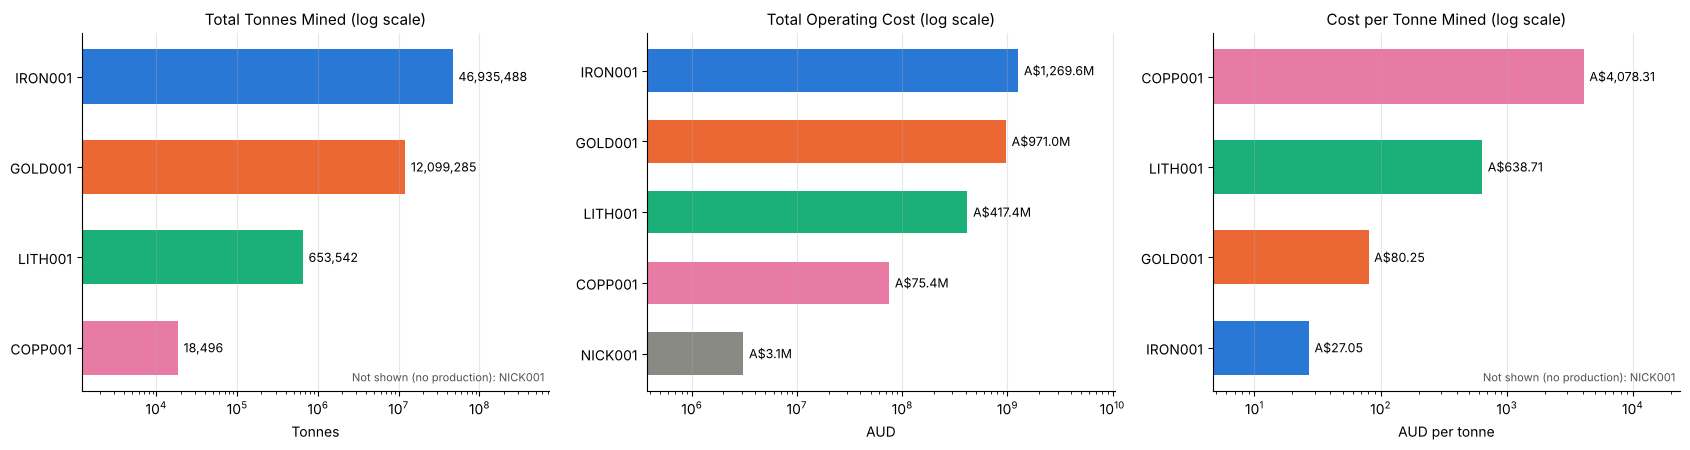

In [11]:
def barh_log(ax, data, column, title, xlabel, formatter):
    # Horizontal bars on a log scale: site values differ by up to ~2,500 times
    plot_data = data[data[column] > 0].sort_values(column)
    bars = ax.barh(
        plot_data["site_id"], plot_data[column],
        color=[SITE_COLORS[s] for s in plot_data["site_id"]], height=0.6,
    )
    ax.set_xscale("log")
    ax.bar_label(bars, labels=[formatter(v) for v in plot_data[column]], padding=4, fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.35)
    ax.grid(axis="y", visible=False)
    missing = sorted(set(data["site_id"]) - set(plot_data["site_id"]))
    if missing:
        ax.text(0.99, 0.02, "Not shown (no production): " + ", ".join(missing),
                transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="#52514e")


fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
barh_log(axes[0], site_summary, "total_tonnes_mined", "Total Tonnes Mined (log scale)",
         "Tonnes", lambda v: f"{v:,.0f}")
barh_log(axes[1], site_summary, "total_cost_aud", "Total Operating Cost (log scale)",
         "AUD", lambda v: f"A${v / 1e6:,.1f}M")
barh_log(axes[2], site_summary, "cost_per_tonne_mined_aud", "Cost per Tonne Mined (log scale)",
         "AUD per tonne", lambda v: f"A${v:,.2f}")
plt.tight_layout()
plt.show()

**Interpretasi**

| Lokasi | Ton ditambang | Biaya total (A$) | Biaya per ton (A$) |
|---|---|---|---|
| Iron Ridge | 46.935.488 | sekitar 1.269,6 juta | 27,05 |
| Golden Valley | 12.099.285 | sekitar 971,0 juta | 80,25 |
| Lithium Creek | 653.542 | sekitar 417,4 juta | 638,71 |
| Copper Hills | 18.496 | sekitar 75,4 juta | 4.078,31 |
| Nickel Point | 0 | sekitar 3,1 juta | tidak terdefinisi |

- **Iron Ridge** adalah lokasi terbesar: sekitar 78,6% dari seluruh ton ditambang dan sekitar 46,4% dari seluruh biaya. Golden Valley menyumbang sekitar 20,3% ton dan 35,5% biaya, sedangkan Lithium Creek sekitar 1,1% ton tetapi 15,3% biaya.
- Biaya per ton berbeda sekitar **150 kali** antara Iron Ridge dan Copper Hills, sementara volume produksinya berbeda sekitar 2.500 kali. Selisih ini mencerminkan komoditas dan skala yang berbeda, bukan bahwa Iron Ridge "150 kali lebih efisien". Karena itu grafik memakai skala logaritmik, dan perbandingan yang adil adalah terhadap target dan tren lokasi itu sendiri (kolom `cost_vs_target_pct`, serta Section 6).
- Keempat lokasi produksi mencapai sekitar **92,5% hingga 93,9%** dari target tonase tahunan, dengan kepatuhan rencana rata-rata 92,1% hingga 93,8%. Tidak ada lokasi yang mencapai target penuh.
- **Perbandingan dengan target biaya** harus memakai basis yang tepat (lihat Section 2.3). Iron Ridge sekitar **+0,2%** di atas target A$27,00 per ton. Golden Valley sekitar **6,0% di bawah** target A$2.500 per unit logam (A$2.351 per unit). Lithium Creek cocok dengan targetnya (A$640) hanya bila dihitung per ton ditambang (A$638,71, sekitar −0,2%), bukan per unit logam. **Copper Hills tidak dapat dibandingkan**: biaya aktual sekitar A$79 per pon, sedangkan targetnya A$1,85, atau sekitar 43 kali lipat. Ini menunjukkan target tembaga tidak konsisten dengan skala data sintetisnya.
- Copper Hills memiliki biaya per ton tertinggi karena volumenya sangat kecil (18.496 ton setahun) dibanding biaya tahunan sekitar A$75 juta. Skala ini tidak lazim untuk tambang tembaga dan sebaiknya dibaca sebagai karakteristik data sintetis.

## 4. Cost Structure

Apa saja yang membentuk biaya setiap lokasi? Tujuh komponen biaya dijumlahkan per lokasi dan dinyatakan sebagai persentase dari total biaya lokasi itu.

,site_id,labor_share_pct,equipment_share_pct,fuel_share_pct,maintenance_share_pct,consumables_share_pct,utilities_share_pct,admin_share_pct
0,IRON001,40.00,28.0,18.0,8.00,4.0,1.00,1.00
1,GOLD001,40.00,28.0,18.0,8.00,4.0,1.00,1.00
2,LITH001,40.00,28.0,18.0,8.00,4.0,1.00,1.00
3,COPP001,40.00,28.0,18.0,8.00,4.0,1.00,1.00
4,NICK001,58.82,0.0,0.0,23.53,0.0,11.76,5.88


Largest difference in any cost component share between producing sites: 0.00 percentage points
Largest cost component by site:
site_id
IRON001    labor
GOLD001    labor
LITH001    labor
COPP001    labor
NICK001    labor


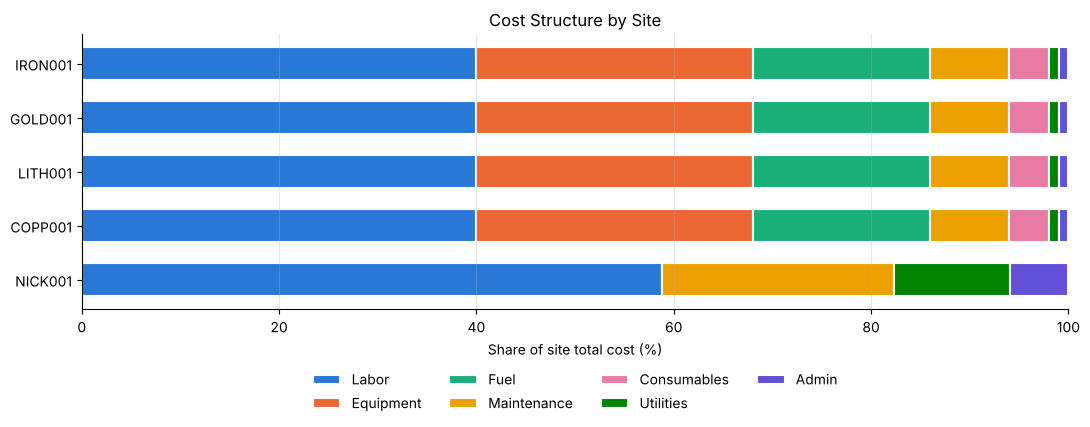

In [12]:
cost_structure = merged.groupby("site_id")[COST_COLUMNS + ["total_cost_aud"]].sum()
cost_structure = cost_structure.reindex(
    [s for s in site_summary["site_id"]]
)

share_columns = {c: c.replace("_cost_aud", "") + "_share_pct" for c in COST_COLUMNS}
cost_share = cost_structure[COST_COLUMNS].div(cost_structure["total_cost_aud"], axis=0) * 100
cost_share = cost_share.rename(columns=share_columns)

cost_structure_table = cost_structure.join(cost_share).reset_index()
display(cost_share.round(2).reset_index())

# Do the producing sites share the same cost structure?
operating_sites = site_summary.loc[site_summary["total_tonnes_mined"] > 0, "site_id"].tolist()
share_spread = (cost_share.loc[operating_sites].max() - cost_share.loc[operating_sites].min()).max()
print(f"Largest difference in any cost component share between producing sites: {share_spread:.2f} percentage points")
print("Largest cost component by site:")
print(cost_share.idxmax(axis=1).str.replace("_share_pct", "").to_string())

# Stacked 100% bars
component_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
labels = [c.replace("_cost_aud", "").capitalize() for c in COST_COLUMNS]

fig, ax = plt.subplots(figsize=(11, 4.5))
left = np.zeros(len(cost_share))
for column, color, label in zip(share_columns.values(), component_colors, labels):
    ax.barh(cost_share.index, cost_share[column], left=left, color=color, label=label,
            edgecolor="white", linewidth=1.5, height=0.62)
    left += cost_share[column].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of site total cost (%)")
ax.set_title("Cost Structure by Site")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

**Interpretasi**

- **Keempat lokasi produksi memiliki struktur biaya yang persis sama** (selisih 0,00 poin persentase): tenaga kerja 40%, peralatan 28%, bahan bakar 18%, perawatan 8%, bahan habis pakai 4%, utilitas 1%, administrasi 1%. Perbedaan biaya antar lokasi murni berasal dari skala, bukan dari komposisi.
- **Nickel Point** berbeda: tenaga kerja sekitar 58,8%, perawatan 23,5%, utilitas 11,8%, dan administrasi 5,9%, tanpa biaya peralatan, bahan bakar, atau bahan habis pakai, sesuai statusnya sebagai lokasi yang tidak berproduksi.
- Karena struktur biaya seragam, analisis penghematan per komponen tidak akan menunjukkan lokasi yang "boros" pada komponen tertentu. Tenaga kerja dan peralatan bersama-sama sekitar 68% dari biaya, sehingga keduanya tempat terbesar untuk mencari efisiensi.

## 5. Production Volume vs Operating Cost

Pertanyaan kunci 4: bagaimana biaya harian berubah bila produksi harian berubah? Untuk setiap lokasi produksi, biaya harian diregresikan terhadap ton ditambang harian dengan garis lurus:

`biaya harian = biaya tetap per hari + biaya variabel per ton × ton harian`

Kemiringan garis adalah **biaya variabel per ton**, dan titik potong adalah perkiraan **biaya tetap per hari**. Ini regresi linear sederhana pada satu lokasi, bukan pemisahan biaya akuntansi.

In [13]:
relationship_rows = []
for site_id in site_summary["site_id"]:
    group = merged[merged["site_id"] == site_id]
    x = group["tonnes_mined"].to_numpy(dtype=float)
    y = group["total_cost_aud"].to_numpy(dtype=float)

    row = {
        "site_id": site_id,
        "days": len(group),
        "avg_daily_tonnes": x.mean(),
        "avg_daily_cost_aud": y.mean(),
    }

    if x.std() == 0:
        # No variation in production (Nickel Point): the whole cost is fixed
        row.update({"fixed_cost_per_day_aud": y.mean(), "fixed_cost_share_pct": 100.0})
    else:
        slope, intercept = np.polyfit(x, y, 1)
        fitted = slope * x + intercept
        cost_per_tonne_daily = y / x if (x > 0).all() else np.full_like(x, np.nan)
        row.update({
            "corr_tonnes_vs_cost": np.corrcoef(x, y)[0, 1],
            "variable_cost_per_tonne_aud": slope,
            "fixed_cost_per_day_aud": intercept,
            "fixed_cost_share_pct": intercept * len(group) / y.sum() * 100,
            "r2_linear_fit": 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "corr_tonnes_vs_cost_per_tonne": np.corrcoef(x, cost_per_tonne_daily)[0, 1],
            "daily_cost_per_tonne_cv_pct": np.nanstd(cost_per_tonne_daily) / np.nanmean(cost_per_tonne_daily) * 100,
        })
    relationship_rows.append(row)

relationship = pd.DataFrame(relationship_rows)
display(relationship.round(3))

# Compare the fitted variable cost with the realised cost per tonne
check = relationship.merge(
    site_summary[["site_id", "cost_per_tonne_mined_aud"]], on="site_id"
)
check["variable_vs_average_cost_pct"] = (
    check["variable_cost_per_tonne_aud"] / check["cost_per_tonne_mined_aud"] * 100
)
display(check[["site_id", "variable_cost_per_tonne_aud", "cost_per_tonne_mined_aud", "variable_vs_average_cost_pct"]].round(2))

,site_id,days,avg_daily_tonnes,avg_daily_cost_aud,corr_tonnes_vs_cost,variable_cost_per_tonne_aud,fixed_cost_per_day_aud,fixed_cost_share_pct,r2_linear_fit,corr_tonnes_vs_cost_per_tonne,daily_cost_per_tonne_cv_pct
0,IRON001,365,128590.378,3478427.239,0.980,26.985,8466.900,0.243,0.961,-0.020,2.716
1,GOLD001,365,33148.726,2660155.665,0.975,78.690,51686.050,1.943,0.951,-0.154,3.002
2,LITH001,365,1790.526,1143625.399,0.978,636.495,3965.325,0.347,0.956,-0.003,2.877
3,COPP001,365,50.674,206664.101,0.978,4039.596,1961.715,0.949,0.956,-0.023,2.890
4,NICK001,365,0.000,8500.000,NaN,NaN,8500.000,100.000,NaN,NaN,NaN


,site_id,variable_cost_per_tonne_aud,cost_per_tonne_mined_aud,variable_vs_average_cost_pct
0,IRON001,26.98,27.05,99.76
1,GOLD001,78.69,80.25,98.06
2,LITH001,636.49,638.71,99.65
3,COPP001,4039.60,4078.31,99.05
4,NICK001,NaN,NaN,NaN


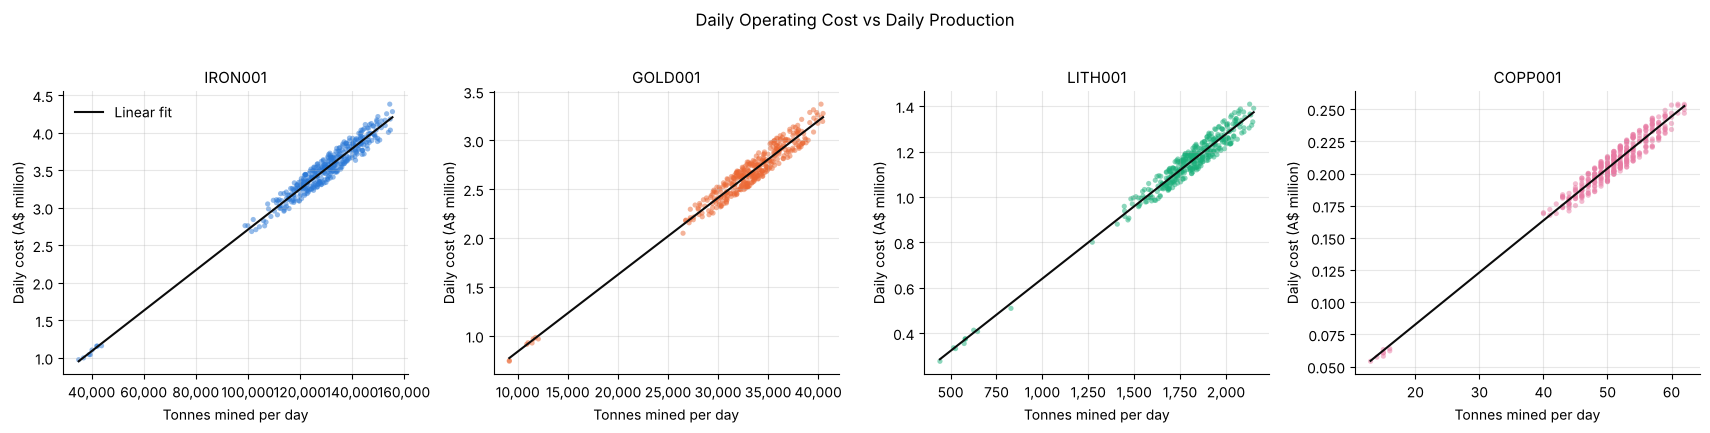

In [14]:
fig, axes = plt.subplots(1, len(operating_sites), figsize=(4.3 * len(operating_sites), 4.2))
axes = np.atleast_1d(axes)

for ax, site_id in zip(axes, operating_sites):
    group = merged[merged["site_id"] == site_id]
    x = group["tonnes_mined"].to_numpy(dtype=float)
    y = group["total_cost_aud"].to_numpy(dtype=float) / 1e6
    slope, intercept = np.polyfit(x, y, 1)
    grid = np.linspace(x.min(), x.max(), 50)
    ax.scatter(x, y, s=14, alpha=0.5, color=SITE_COLORS[site_id], edgecolors="none")
    ax.plot(grid, slope * grid + intercept, color="#0b0b0b", linewidth=1.5, label="Linear fit")
    ax.set_title(site_id, fontsize=11)
    ax.set_xlabel("Tonnes mined per day")
    ax.set_ylabel("Daily cost (A$ million)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Daily Operating Cost vs Daily Production", y=1.02)
plt.tight_layout()
plt.show()

In [15]:
operating_relationship = relationship[relationship["site_id"].isin(operating_sites)]
print("Fit quality (R² of the linear fit), producing sites:")
print(operating_relationship.set_index("site_id")["r2_linear_fit"].round(4).to_string())
print("\nFixed cost as share of total site cost (%):")
print(operating_relationship.set_index("site_id")["fixed_cost_share_pct"].round(1).to_string())
print("\nCorrelation between daily tonnes and daily cost per tonne:")
print(operating_relationship.set_index("site_id")["corr_tonnes_vs_cost_per_tonne"].round(3).to_string())

Fit quality (R² of the linear fit), producing sites:
site_id
IRON001    0.9607
GOLD001    0.9507
LITH001    0.9560
COPP001    0.9562

Fixed cost as share of total site cost (%):
site_id
IRON001    0.2
GOLD001    1.9
LITH001    0.3
COPP001    0.9

Correlation between daily tonnes and daily cost per tonne:
site_id
IRON001   -0.020
GOLD001   -0.154
LITH001   -0.003
COPP001   -0.023


**Interpretasi**

- **Biaya harian hampir sepenuhnya mengikuti produksi harian.** Korelasi ton dan biaya sekitar 0,975 hingga 0,980 pada keempat lokasi, dan garis lurus menjelaskan sekitar 95% hingga 96% variasi biaya harian.
- **Bagian biaya tetap sangat kecil**: perkiraan hanya sekitar 0,2% dari biaya total (Iron Ridge), 0,3% (Lithium Creek), 0,9% (Copper Hills), dan 1,9% (Golden Valley). Biaya variabel per ton dari regresi mencapai sekitar 98% hingga 99,8% dari biaya rata-rata per ton.
- **Tidak ada skala ekonomi yang jelas.** Korelasi antara ton harian dan biaya per ton berkisar −0,15 hingga 0 (terkuat di Golden Valley), dan biaya per ton harian hanya bervariasi sekitar 2,7% hingga 3,0% di sekitar rata-ratanya. Hari berproduksi tinggi tidak berbiaya per ton jauh lebih rendah.
- **Nickel Point**: seluruh biaya bersifat tetap (sekitar A$8.500 per hari), karena tidak ada produksi.
- Pola biaya yang hampir sepenuhnya variabel tidak lazim untuk tambang sungguhan, yang umumnya memiliki biaya tetap besar. Ini ciri data sintetis, dan hasilnya tidak boleh dibaca sebagai karakter operasi tambang nyata.
- Hubungan ini diukur pada satu tahun data sintetis di dalam rentang produksi yang teramati, dan tidak boleh diekstrapolasi ke volume di luar rentang itu.

## 6. Monthly Trends

Jumlah hari per bulan berbeda (28 sampai 31), sehingga total bulanan tidak dibandingkan langsung. Produksi dan biaya dinyatakan **per hari**, lalu dinormalisasi menjadi **indeks terhadap rata-rata tahunan lokasi itu (= 100)**. Dengan indeks, empat lokasi dengan skala sangat berbeda dapat digambar pada satu sumbu.

In [16]:
monthly_site = (
    merged.groupby(["month_start", "site_id"])
    .agg(
        days=("date", "count"),
        tonnes_mined=("tonnes_mined", "sum"),
        total_cost_aud=("total_cost_aud", "sum"),
    )
    .reset_index()
)

monthly_site["tonnes_per_day"] = monthly_site["tonnes_mined"] / monthly_site["days"]
monthly_site["cost_per_day_aud"] = monthly_site["total_cost_aud"] / monthly_site["days"]
monthly_site["cost_per_tonne_aud"] = monthly_site["total_cost_aud"] / monthly_site["tonnes_mined"].where(monthly_site["tonnes_mined"] > 0)

# Annual references per site (weighted by days / tonnes)
annual_tonnes_per_day = merged.groupby("site_id")["tonnes_mined"].sum() / merged.groupby("site_id").size()
annual_cost_per_tonne = site_summary.set_index("site_id")["cost_per_tonne_mined_aud"]

monthly_site["tonnes_per_day_index"] = (
    monthly_site["tonnes_per_day"] / monthly_site["site_id"].map(annual_tonnes_per_day).where(lambda s: s > 0) * 100
)
monthly_site["cost_per_tonne_index"] = (
    monthly_site["cost_per_tonne_aud"] / monthly_site["site_id"].map(annual_cost_per_tonne) * 100
)
monthly_site["cost_per_day_index"] = (
    monthly_site["cost_per_day_aud"]
    / (monthly_site["site_id"].map(site_summary.set_index("site_id")["avg_daily_cost_aud"])) * 100
)

variation_rows = []
for site_id in operating_sites:
    g = monthly_site[monthly_site["site_id"] == site_id]
    variation_rows.append({
        "site_id": site_id,
        "tonnes_per_day_index_min": g["tonnes_per_day_index"].min(),
        "tonnes_per_day_index_max": g["tonnes_per_day_index"].max(),
        "cost_per_tonne_index_min": g["cost_per_tonne_index"].min(),
        "cost_per_tonne_index_max": g["cost_per_tonne_index"].max(),
        "lowest_cost_per_tonne_month": g.loc[g["cost_per_tonne_index"].idxmin(), "month_start"].strftime("%b"),
        "highest_cost_per_tonne_month": g.loc[g["cost_per_tonne_index"].idxmax(), "month_start"].strftime("%b"),
    })
monthly_variation = pd.DataFrame(variation_rows).round(2)
display(monthly_variation)

# Company-wide monthly cost (currency can be added across sites; tonnes of different commodities cannot)
monthly_total = (
    merged.groupby("month_start")
    .agg(total_cost_aud=("total_cost_aud", "sum"), days=("date", "nunique"))
    .assign(cost_per_day_aud=lambda t: t["total_cost_aud"] / t["days"])
    .round(2)
    .reset_index()
)
display(monthly_total)

,site_id,tonnes_per_day_index_min,tonnes_per_day_index_max,cost_per_tonne_index_min,cost_per_tonne_index_max,lowest_cost_per_tonne_month,highest_cost_per_tonne_month
0,IRON001,96.58,104.28,99.35,100.75,Aug,May
1,GOLD001,95.40,104.62,99.42,100.93,May,Aug
2,LITH001,93.65,103.90,99.18,101.13,Dec,Oct
3,COPP001,94.53,105.05,99.33,100.84,Jan,Feb


,month_start,total_cost_aud,days,cost_per_day_aud
0,2025-01-01,2.369644e+08,31,7644014.00
1,2025-02-01,2.181239e+08,28,7790137.67
2,2025-03-01,2.265720e+08,31,7308775.21
3,2025-04-01,2.215668e+08,30,7385560.28
4,2025-05-01,2.356614e+08,31,7601979.09
5,2025-06-01,2.155752e+08,30,7185840.02
6,2025-07-01,2.362305e+08,31,7620338.90
7,2025-08-01,2.379276e+08,31,7675083.86
8,2025-09-01,2.181232e+08,30,7270774.94
9,2025-10-01,2.346739e+08,31,7570125.70


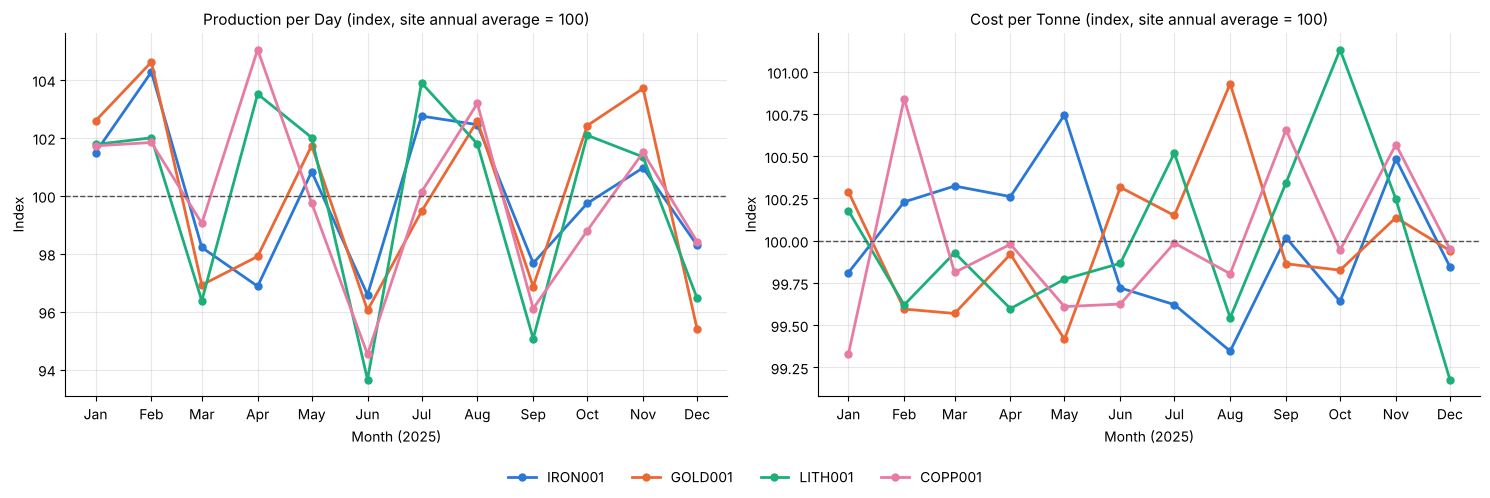

In [17]:
month_axis = mdates.DateFormatter("%b")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
panels = [
    ("tonnes_per_day_index", "Production per Day (index, site annual average = 100)"),
    ("cost_per_tonne_index", "Cost per Tonne (index, site annual average = 100)"),
]

for ax, (column, title) in zip(axes, panels):
    for site_id in operating_sites:
        site_data = monthly_site[monthly_site["site_id"] == site_id]
        ax.plot(site_data["month_start"], site_data[column], marker="o", markersize=5,
                linewidth=2, color=SITE_COLORS[site_id], label=site_id)
    ax.axhline(100, color="#52514e", linewidth=1, linestyle="--")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Month (2025)")
    ax.set_ylabel("Index")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(month_axis)

handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, ncol=len(labels_), frameon=False, loc="lower center")
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

**Interpretasi**

- Tabel `monthly_variation` merangkum rentang indeks bulanan tiap lokasi. Indeks 100 berarti sama dengan rata-rata tahunan lokasi itu.
- **Produksi per hari** berfluktuasi sekitar ±5% di sekitar rata-rata: indeks terendah sekitar 93,7 (Lithium Creek) dan tertinggi sekitar 105,1 (Copper Hills). Tidak ada tren naik atau turun yang jelas sepanjang tahun.
- **Biaya per ton sangat stabil**: indeks bulanan hanya berkisar sekitar 99,2 hingga 101,1 (sekitar ±1%) di keempat lokasi. Bulan dengan biaya per ton tertinggi dan terendah berbeda-beda antar lokasi, jadi tidak ada pola musiman. Ini sejalan dengan Section 5: biaya per ton hampir tidak bergantung pada volume.
- Biaya total gabungan seluruh lokasi berkisar sekitar A$7,19 juta per hari (Juni) hingga A$7,79 juta per hari (Februari). Biaya hanya dijumlahkan dalam dolar. Ton antar komoditas **tidak dijumlahkan** per bulan, karena bijih besi, emas, lithium, dan tembaga tidak sebanding, dan total gabungannya hampir seluruhnya ditentukan Iron Ridge (sekitar 78,6% ton).
- Data hanya mencakup satu tahun, sehingga pola musiman tidak bisa dipastikan.

### 6.1 Downtime days

Produksi harian bergerak dalam rentang sempit, kecuali pada hari dengan `downtime_hours` > 0. Bagian ini mengukur seberapa besar hari-hari itu memotong produksi, karena hari seperti ini juga yang paling sulit diperkirakan oleh model di Section 7.

In [18]:
producing_data = merged[merged["site_id"].isin(operating_sites)].copy()
producing_data["downtime_day"] = producing_data["downtime_hours"] > 0
producing_data["weather_day"] = producing_data["weather_delay_hours"] > 0

downtime_rows = []
for site_id in operating_sites:
    g = producing_data[producing_data["site_id"] == site_id]
    down, normal = g[g["downtime_day"]], g[~g["downtime_day"]]
    downtime_rows.append({
        "site_id": site_id,
        "downtime_days": len(down),
        "of_which_weather_delay_days": int(down["weather_day"].sum()),
        "avg_downtime_hours": down["downtime_hours"].mean(),
        "avg_operational_hours": down["operational_hours"].mean(),
        "tonnes_pct_of_normal_day": down["tonnes_mined"].mean() / normal["tonnes_mined"].mean() * 100,
        "plan_adherence_downtime_days_pct": down["plan_adherence_pct"].mean(),
        "plan_adherence_normal_days_pct": normal["plan_adherence_pct"].mean(),
    })
downtime_summary = pd.DataFrame(downtime_rows).round(1)
display(downtime_summary)

downtime_dates = (
    producing_data[producing_data["downtime_day"] & ~producing_data["weather_day"]]
    .groupby("date")["site_id"].nunique().rename("sites_affected").reset_index()
)
print("Dates with downtime (excluding weather-delay days):")
display(downtime_dates)

,site_id,downtime_days,of_which_weather_delay_days,avg_downtime_hours,avg_operational_hours,tonnes_pct_of_normal_day,plan_adherence_downtime_days_pct,plan_adherence_normal_days_pct
0,IRON001,8,0,16.8,7.2,30.5,29.1,95.3
1,GOLD001,8,0,16.8,7.2,32.3,30.6,94.4
2,LITH001,10,2,15.4,8.6,36.2,34.3,94.9
3,COPP001,8,0,16.8,7.2,28.9,27.1,93.6


Dates with downtime (excluding weather-delay days):


,date,sites_affected
0,2025-03-15,4
1,2025-03-16,4
2,2025-06-15,4
3,2025-06-16,4
4,2025-09-15,4
5,2025-09-16,4
6,2025-12-15,4
7,2025-12-16,4


**Interpretasi**

- Setiap lokasi produksi memiliki **8 hari downtime** (Lithium Creek 10, dua di antaranya karena cuaca). Pada hari itu produksi turun hanya ke sekitar **29% hingga 36%** dari hari normal, dengan rata-rata sekitar 15 hingga 17 jam downtime per hari.
- Hari downtime jatuh pada **tanggal yang sama untuk keempat lokasi**: 15 dan 16 pada Maret, Juni, September, dan Desember. Polanya berulang tiap kuartal dan terjadi serentak, sehingga lebih mirip penghentian terjadwal daripada kerusakan acak.
- Kepatuhan rencana pada hari-hari itu hanya sekitar 27% hingga 34%, dibanding sekitar 94% hingga 95% pada hari normal. Hari downtime menurunkan rata-rata kepatuhan rencana tahunan sekitar 1,4 hingga 1,7 poin.
- Karena hari downtime sangat berbeda dari hari biasa dan hanya 8 dari 365 hari, model biaya di Section 7 paling sulit memperkirakannya.

## 7. Cost Estimation Model

### Purpose and design

Model ini **memperkirakan biaya operasi harian dari lokasi, kalender, dan ton ditambang hari itu**. Ini estimasi biaya untuk volume produksi tertentu (mis. untuk anggaran skenario), bukan peramalan masa depan, karena ton ditambang harus diketahui.

- **Target:** `total_cost_aud` per lokasi per hari.
- **Fitur:** `site_id`, `month_num`, `day_of_week`, `day_of_year`, `tonnes_mined` (sama dengan versi sebelumnya).
- **Pembagian data berdasarkan waktu:** 80% tanggal paling awal untuk latih, 20% tanggal terakhir untuk uji. Pembagian dilakukan **per tanggal**, sehingga semua lokasi pada satu tanggal berada di sisi yang sama.
- **Pembanding (baseline):** (A) rata-rata biaya harian per lokasi, dan (B) regresi linear biaya terhadap ton per lokasi. Random Forest baru layak dipakai bila lebih baik daripada baseline sederhana ini.
- Karena biaya harian sangat bergantung pada tonase (Section 5), akurasi tinggi diharapkan. Model ini adalah tolok ukur, bukan temuan baru.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

TARGET = "total_cost_aud"
FEATURES = ["site_id", "month_num", "day_of_week", "day_of_year", "tonnes_mined"]

ml_df = merged[["date", "site_id", "tonnes_mined", TARGET, "downtime_hours"]].copy()
ml_df["month_num"] = ml_df["date"].dt.month
ml_df["day_of_week"] = ml_df["date"].dt.dayofweek
ml_df["day_of_year"] = ml_df["date"].dt.dayofyear
ml_df = ml_df.dropna(subset=FEATURES + [TARGET]).sort_values(["date", "site_id"]).reset_index(drop=True)

# Time-based split by date (80% / 20%)
unique_dates = np.sort(ml_df["date"].unique())
cutoff_date = unique_dates[int(len(unique_dates) * 0.8)]
train = ml_df[ml_df["date"] < cutoff_date]
test = ml_df[ml_df["date"] >= cutoff_date]

assert train["date"].max() < test["date"].min(), "Training and test dates overlap."

print("Training rows:", len(train), "|", train["date"].min().date(), "to", train["date"].max().date())
print("Testing rows: ", len(test), "|", test["date"].min().date(), "to", test["date"].max().date())

# How many test days fall outside the production range seen in training? (matters for tree models)
train_range = train.groupby("site_id")["tonnes_mined"].agg(["min", "max"])
above_range = int((test["tonnes_mined"] > test["site_id"].map(train_range["max"])).sum())
below_range = int((test["tonnes_mined"] < test["site_id"].map(train_range["min"])).sum())
print("Test records with tonnes_mined above the training maximum of their site:", above_range)
print("Test records with tonnes_mined below the training minimum of their site:", below_range)

Training rows: 1460 | 2025-01-01 to 2025-10-19
Testing rows:  365 | 2025-10-20 to 2025-12-31
Test records with tonnes_mined above the training maximum of their site: 1
Test records with tonnes_mined below the training minimum of their site: 2


### 7.1 Fit the models

In [20]:
predictions = {}

# Baseline A: average daily cost of each site in the training period
site_mean_cost = train.groupby("site_id")[TARGET].mean()
predictions["A: Site average"] = test["site_id"].map(site_mean_cost)

# Baseline B: one straight line (cost vs tonnes) per site
linear_models = {
    site_id: LinearRegression().fit(group[["tonnes_mined"]], group[TARGET])
    for site_id, group in train.groupby("site_id")
}
linear_pred = pd.Series(index=test.index, dtype=float)
for site_id, group in test.groupby("site_id"):
    linear_pred.loc[group.index] = linear_models[site_id].predict(group[["tonnes_mined"]])
predictions["B: Linear per site"] = linear_pred

# Random Forest (same settings as the previous version of this notebook)
categorical_features = ["site_id"]
numeric_features = [c for c in FEATURES if c not in categorical_features]

rf_model = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("site", OneHotEncoder(handle_unknown="ignore"), categorical_features),
            ("numeric", "passthrough", numeric_features),
        ],
        remainder="drop",
    )),
    ("regressor", RandomForestRegressor(
        n_estimators=100, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1,
    )),
])
rf_model.fit(train[FEATURES], train[TARGET])
predictions["C: Random Forest"] = pd.Series(rf_model.predict(test[FEATURES]), index=test.index)

print("Models fitted:", ", ".join(predictions))

Models fitted: A: Site average, B: Linear per site, C: Random Forest


### 7.2 Evaluation

Metrik gabungan (R², RMSE) didominasi oleh lokasi bervolume besar, karena biaya Iron Ridge ribuan kali lipat biaya Copper Hills. Karena itu galat juga dihitung **per lokasi** dalam persen (MAPE), yang sebanding antar lokasi.

In [21]:
def regression_metrics(actual, predicted):
    error = actual - predicted
    return {
        "MAE_aud": mean_absolute_error(actual, predicted),
        "RMSE_aud": float(np.sqrt(mean_squared_error(actual, predicted))),
        "R2": r2_score(actual, predicted),
        "WAPE_pct": error.abs().sum() / actual.sum() * 100,
    }


actual = test[TARGET]

overall_metrics = pd.DataFrame(
    {name: regression_metrics(actual, pred) for name, pred in predictions.items()}
).T.rename_axis("model").reset_index()
display(overall_metrics.round({"MAE_aud": 0, "RMSE_aud": 0, "R2": 4, "WAPE_pct": 2}))

site_rows = []
for name, pred in predictions.items():
    for site_id, index in test.groupby("site_id").groups.items():
        a, p = actual.loc[index], pred.loc[index]
        site_rows.append({
            "model": name,
            "site_id": site_id,
            "avg_actual_cost_aud": a.mean(),
            "MAE_aud": (a - p).abs().mean(),
            "MAPE_pct": ((a - p).abs() / a).mean() * 100,
        })
site_metrics = pd.DataFrame(site_rows)

print("Mean absolute percentage error (MAPE, %) by site and model:")
display(site_metrics.pivot(index="site_id", columns="model", values="MAPE_pct").reindex(site_summary["site_id"]).round(2))
print("Mean absolute error (A$) by site and model:")
display(site_metrics.pivot(index="site_id", columns="model", values="MAE_aud").reindex(site_summary["site_id"]).round(0))

,model,MAE_aud,RMSE_aud,R2,WAPE_pct
0,A: Site average,138207.0,300964.0,0.9531,9.25
1,B: Linear per site,37038.0,57361.0,0.9983,2.48
2,C: Random Forest,44426.0,78984.0,0.9968,2.97


Mean absolute percentage error (MAPE, %) by site and model:


model,A: Site average,B: Linear per site,C: Random Forest
site_id,,,
IRON001,13.80,2.41,4.16
GOLD001,13.11,2.55,2.97
LITH001,12.94,2.61,3.22
COPP001,14.36,2.51,2.67
NICK001,0.00,0.00,0.00


Mean absolute error (A$) by site and model:


model,A: Site average,B: Linear per site,C: Random Forest
site_id,,,
IRON001,327484.0,83373.0,108959.0
GOLD001,240213.0,66993.0,71477.0
LITH001,103231.0,29884.0,36334.0
COPP001,20106.0,4939.0,5360.0
NICK001,0.0,0.0,0.0


### 7.3 Which inputs does the Random Forest use?

Permutation importance diukur pada data uji: nilai satu fitur diacak, lalu dilihat seberapa besar MAE naik. Semakin besar kenaikan MAE, semakin penting fitur itu.

,feature,mae_increase_aud,std
0,tonnes_mined,1491570.0,33173.0
1,site_id,61652.0,5361.0
2,day_of_week,99.0,589.0
3,day_of_year,-0.0,0.0
4,month_num,-0.0,0.0


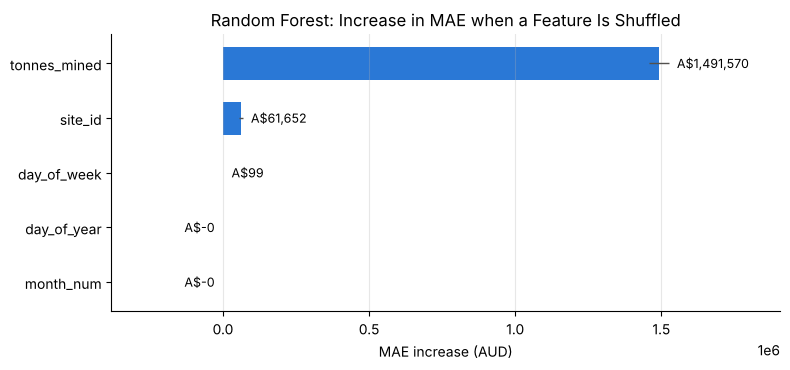

In [22]:
perm = permutation_importance(
    rf_model, test[FEATURES], test[TARGET],
    n_repeats=10, random_state=42, scoring="neg_mean_absolute_error", n_jobs=-1,
)
importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "mae_increase_aud": perm.importances_mean,
        "std": perm.importances_std,
    })
    .sort_values("mae_increase_aud", ascending=False)
    .reset_index(drop=True)
)
display(importance.round(0))

plot_importance = importance.sort_values("mae_increase_aud")
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(plot_importance["feature"], plot_importance["mae_increase_aud"],
               xerr=plot_importance["std"], color="#2a78d6", height=0.6,
               error_kw={"ecolor": "#52514e", "elinewidth": 1})
ax.bar_label(bars, labels=[f"A${v:,.0f}" for v in plot_importance["mae_increase_aud"]], padding=6, fontsize=9)
ax.set_title("Random Forest: Increase in MAE when a Feature Is Shuffled")
ax.set_xlabel("MAE increase (AUD)")
ax.margins(x=0.25)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 7.4 Actual vs predicted, and error by site

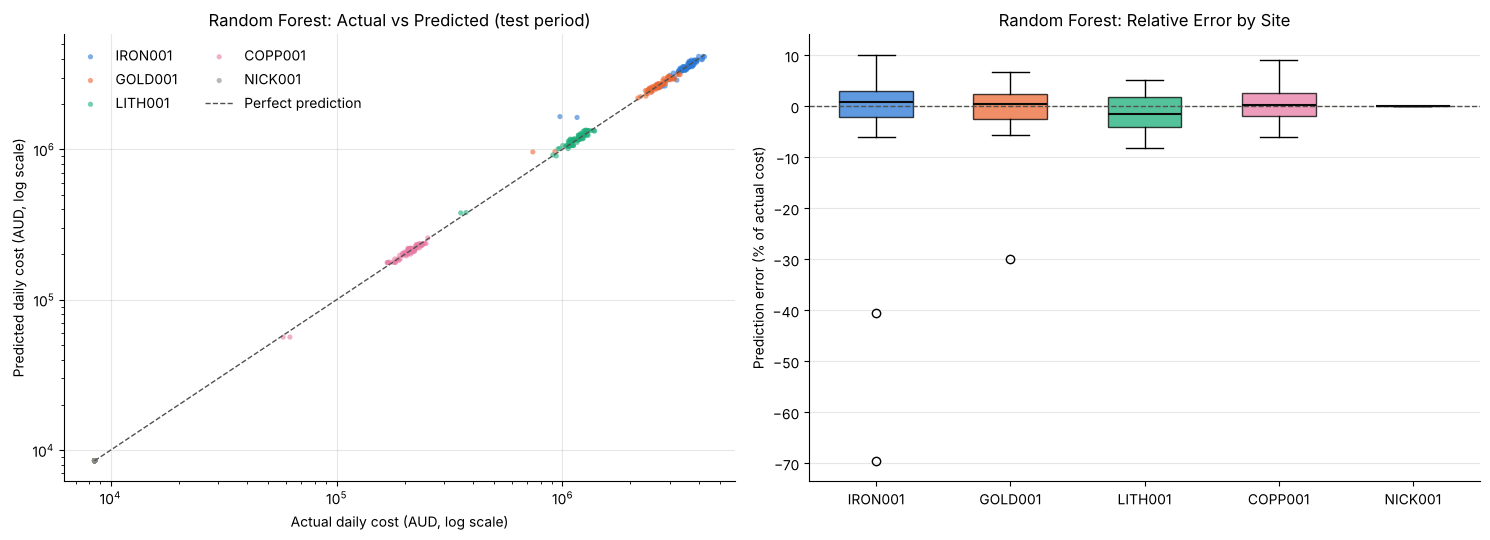

10 largest prediction errors (Random Forest):


,date,site_id,tonnes_mined,actual_cost_aud,predicted_random_forest_aud,rf_error_aud,rf_abs_pct_error
1742,2025-12-15,IRON001,35029,974467.59,1651540.06,-677072.47,69.48
1747,2025-12-16,IRON001,43811,1160131.26,1630053.11,-469921.85,40.51
1632,2025-11-23,IRON001,114808,3209726.74,2884599.11,325127.63,10.13
1741,2025-12-15,GOLD001,9153,739162.05,960899.39,-221737.34,30.00
1497,2025-10-27,IRON001,141409,3632979.52,3848561.60,-215582.08,5.93
1631,2025-11-23,GOLD001,37498,3137722.39,2925368.62,212353.77,6.77
1807,2025-12-28,IRON001,102101,2843504.50,2636168.29,207336.21,7.29
1512,2025-10-30,IRON001,133936,3750990.30,3546889.47,204100.83,5.44
1657,2025-11-28,IRON001,144693,3717562.12,3921378.90,-203816.78,5.48
1607,2025-11-18,IRON001,149584,4171351.22,3980895.64,190455.58,4.57


In [23]:
rf_pred = predictions["C: Random Forest"]

results_df = pd.DataFrame({
    "date": test["date"].dt.date,
    "site_id": test["site_id"],
    "tonnes_mined": test["tonnes_mined"],
    "actual_cost_aud": actual,
    "predicted_site_average_aud": predictions["A: Site average"],
    "predicted_linear_aud": predictions["B: Linear per site"],
    "predicted_random_forest_aud": rf_pred,
})
results_df["downtime_day"] = test["downtime_hours"] > 0
results_df["rf_error_aud"] = results_df["actual_cost_aud"] - results_df["predicted_random_forest_aud"]
results_df["rf_abs_pct_error"] = results_df["rf_error_aud"].abs() / results_df["actual_cost_aud"] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
for site_id in site_summary["site_id"]:
    part = results_df[results_df["site_id"] == site_id]
    ax.scatter(part["actual_cost_aud"], part["predicted_random_forest_aud"], s=14, alpha=0.6,
               color=SITE_COLORS[site_id], edgecolors="none", label=site_id)
low = results_df[["actual_cost_aud", "predicted_random_forest_aud"]].min().min()
high = results_df[["actual_cost_aud", "predicted_random_forest_aud"]].max().max()
ax.plot([low, high], [low, high], linestyle="--", color="#52514e", linewidth=1, label="Perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual daily cost (AUD, log scale)")
ax.set_ylabel("Predicted daily cost (AUD, log scale)")
ax.set_title("Random Forest: Actual vs Predicted (test period)")
ax.legend(frameon=False, loc="upper left", ncol=2)

ax = axes[1]
order = list(site_summary["site_id"])
box = ax.boxplot(
    [(results_df.loc[results_df["site_id"] == s, "rf_error_aud"]
      / results_df.loc[results_df["site_id"] == s, "actual_cost_aud"] * 100) for s in order],
    patch_artist=True, tick_labels=order, widths=0.55,
    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
)
for patch, site_id in zip(box["boxes"], order):
    patch.set_facecolor(SITE_COLORS[site_id])
    patch.set_alpha(0.75)
ax.axhline(0, color="#52514e", linewidth=1, linestyle="--")
ax.set_ylabel("Prediction error (% of actual cost)")
ax.set_title("Random Forest: Relative Error by Site")
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print("10 largest prediction errors (Random Forest):")
display(
    results_df.assign(abs_error_aud=results_df["rf_error_aud"].abs())
    .sort_values("abs_error_aud", ascending=False)
    .head(10)[["date", "site_id", "tonnes_mined", "actual_cost_aud", "predicted_random_forest_aud",
               "rf_error_aud", "rf_abs_pct_error"]]
    .round(2)
)

### 7.5 Do downtime days explain the largest errors?

In [24]:
model_columns = {
    "A: Site average": "predicted_site_average_aud",
    "B: Linear per site": "predicted_linear_aud",
    "C: Random Forest": "predicted_random_forest_aud",
}
producing_results = results_df[results_df["site_id"].isin(operating_sites)]
total_abs_error = {
    name: (producing_results["actual_cost_aud"] - producing_results[col]).abs().sum()
    for name, col in model_columns.items()
}

day_type_rows = []
for model_name, column in model_columns.items():
    abs_error = (producing_results["actual_cost_aud"] - producing_results[column]).abs()
    pct_error = abs_error / producing_results["actual_cost_aud"] * 100
    for flag, label in [(False, "Normal days"), (True, "Downtime days")]:
        mask = producing_results["downtime_day"] == flag
        day_type_rows.append({
            "model": model_name,
            "day_type": label,
            "records": int(mask.sum()),
            "MAPE_pct": pct_error[mask].mean(),
            "share_of_total_abs_error_pct": abs_error[mask].sum() / total_abs_error[model_name] * 100,
        })
day_type_errors = pd.DataFrame(day_type_rows).round(2)
display(day_type_errors)

,model,day_type,records,MAPE_pct,share_of_total_abs_error_pct
0,A: Site average,Normal days,284,7.52,79.50
1,A: Site average,Downtime days,8,227.72,20.50
2,B: Linear per site,Normal days,284,2.48,99.00
3,B: Linear per site,Downtime days,8,4.11,1.00
4,C: Random Forest,Normal days,284,2.77,91.08
5,C: Random Forest,Downtime days,8,20.56,8.92


In [25]:
# Plain-language summary of the comparison, computed from the results above
best_model = overall_metrics.loc[overall_metrics["MAE_aud"].idxmin(), "model"]
rf_row = overall_metrics[overall_metrics["model"] == "C: Random Forest"].iloc[0]
lin_row = overall_metrics[overall_metrics["model"] == "B: Linear per site"].iloc[0]
avg_row = overall_metrics[overall_metrics["model"] == "A: Site average"].iloc[0]
rf_site_mape = site_metrics[site_metrics["model"] == "C: Random Forest"].set_index("site_id")["MAPE_pct"]

print(f"Lowest overall MAE: {best_model}")
print(f"Random Forest : MAE A${rf_row['MAE_aud']:,.0f} | RMSE A${rf_row['RMSE_aud']:,.0f} | R² {rf_row['R2']:.4f} | WAPE {rf_row['WAPE_pct']:.2f}%")
print(f"Linear per site: MAE A${lin_row['MAE_aud']:,.0f} | RMSE A${lin_row['RMSE_aud']:,.0f} | R² {lin_row['R2']:.4f} | WAPE {lin_row['WAPE_pct']:.2f}%")
print(f"Site average  : MAE A${avg_row['MAE_aud']:,.0f} | RMSE A${avg_row['RMSE_aud']:,.0f} | R² {avg_row['R2']:.4f} | WAPE {avg_row['WAPE_pct']:.2f}%")
print(f"Random Forest MAE is {rf_row['MAE_aud'] / lin_row['MAE_aud']:.2f}x the linear-per-site MAE.")
print(f"Highest Random Forest MAPE: {rf_site_mape.idxmax()} ({rf_site_mape.max():.2f}%); lowest: {rf_site_mape.idxmin()} ({rf_site_mape.min():.2f}%)")
print("Most important feature:", importance.loc[0, "feature"])

Lowest overall MAE: B: Linear per site
Random Forest : MAE A$44,426 | RMSE A$78,984 | R² 0.9968 | WAPE 2.97%
Linear per site: MAE A$37,038 | RMSE A$57,361 | R² 0.9983 | WAPE 2.48%
Site average  : MAE A$138,207 | RMSE A$300,964 | R² 0.9531 | WAPE 9.25%
Random Forest MAE is 1.20x the linear-per-site MAE.
Highest Random Forest MAPE: IRON001 (4.16%); lowest: NICK001 (0.00%)
Most important feature: tonnes_mined


**Interpretasi**

- **R² gabungan tinggi tidak otomatis berarti model bagus.** Menebak "rata-rata biaya lokasi" saja (model A) sudah memberi R² 0,953, karena biaya antar lokasi berbeda ribuan kali lipat. Karena itu pembanding dan MAPE per lokasi disertakan.
- **Regresi linear per lokasi (B) paling akurat**: MAE sekitar A$37 ribu, R² 0,9983, WAPE 2,48%. Random Forest (C) MAE sekitar A$44 ribu (sekitar 1,2 kali lebih besar), R² 0,9968, WAPE 2,97%. Baseline rata-rata lokasi (A) MAE sekitar A$138 ribu. MAPE per lokasi: model B sekitar 2,4% hingga 2,6%, model C sekitar 2,7% hingga 4,2% (tertinggi di Iron Ridge). Nickel Point 0%, karena biayanya konstan.
- **Random Forest tidak menambah nilai di sini.** Biaya hampir sepenuhnya fungsi linear dari tonase (Section 5), sehingga garis lurus sudah cukup dan lebih mudah dijelaskan. Permutation importance mengonfirmasi hal ini: `tonnes_mined` mendominasi (MAE naik sekitar A$1,5 juta bila diacak), `site_id` kecil (sekitar A$62 ribu), dan fitur kalender praktis nol.
- **Kelemahan Random Forest muncul pada hari downtime** (Section 7.5). Hari uji 15 dan 16 Desember adalah hari downtime, sedangkan data latih hanya memuat 6 hari seperti itu per lokasi. Pada 15 Desember produksi Iron Ridge dan Golden Valley bahkan berada di bawah produksi minimum data latih, dan pohon keputusan tidak dapat mengekstrapolasi di luar rentang latih. Galat Random Forest pada 8 hari downtime itu sekitar 20,6% (MAPE), dibanding sekitar 4,1% untuk regresi linear. Delapan catatan itu menyumbang sekitar 8,9% dari total galat absolut Random Forest, dengan galat terbesar pada Iron Ridge 15 Desember (sekitar 69%, A$677 ribu). Pada hari normal, selisih kedua model kecil (MAPE sekitar 2,8% vs 2,5%), dan regresi linear tetap sedikit lebih baik.
- **Pilihan yang disarankan**: regresi linear per lokasi, ditambah informasi hari downtime bila tersedia di perencanaan. Model dilatih pada satu tahun data sintetis dan tidak boleh dipakai untuk keputusan nyata tanpa divalidasi pada data operasional sesungguhnya.

## 8. Export and Verification

Hasil analisis diekspor ke folder `production_cost_results`: lima tabel CSV, model Random Forest, dan file metrik. Setiap CSV dibaca kembali, dan totalnya dicocokkan dengan database.

In [26]:
export_tables = {
    "site_cost_efficiency_summary.csv": site_summary.round(4),
    "site_cost_structure.csv": cost_structure_table.round(4),
    "production_cost_relationship.csv": relationship.round(6),
    "monthly_site_trends.csv": monthly_site.round({c: 4 for c in monthly_site.select_dtypes("number").columns}),
    "cost_model_predictions.csv": results_df.round(4),
}

for file_name, table in export_tables.items():
    table.to_csv(OUTPUT_DIR / file_name, index=False)

# Trained model and metrics
joblib.dump(rf_model, OUTPUT_DIR / "random_forest_cost_model.joblib")

metrics = {
    "model": "Random Forest Regressor (sklearn Pipeline)",
    "target": TARGET,
    "features": FEATURES,
    "split": "time-based by date, 80% train / 20% test",
    "training_rows": int(len(train)),
    "testing_rows": int(len(test)),
    "test_period": [str(test["date"].min().date()), str(test["date"].max().date())],
    "overall_metrics": overall_metrics.set_index("model").round(4).to_dict(orient="index"),
    "random_forest_mape_pct_by_site": rf_site_mape.round(4).to_dict(),
    "data_type": "Synthetic mining operations data",
}
with open(OUTPUT_DIR / "cost_model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Files written:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

Files written: ['cost_model_metrics.json', 'cost_model_predictions.csv', 'monthly_site_trends.csv', 'production_cost_relationship.csv', 'random_forest_cost_model.joblib', 'site_cost_efficiency_summary.csv', 'site_cost_structure.csv']


In [27]:
exported = {name: pd.read_csv(OUTPUT_DIR / name) for name in export_tables}

db_tonnes = scalar("SELECT SUM(tonnes_mined) FROM daily_production")
db_cost = scalar("SELECT SUM(total_cost_aud) FROM daily_costs")

checks = [
    ("Site summary: total tonnes mined", exported["site_cost_efficiency_summary.csv"]["total_tonnes_mined"].sum(), db_tonnes),
    ("Site summary: total cost (AUD)", exported["site_cost_efficiency_summary.csv"]["total_cost_aud"].sum(), db_cost),
    ("Cost structure: total cost (AUD)", exported["site_cost_structure.csv"]["total_cost_aud"].sum(), db_cost),
    ("Cost structure: sum of the seven components (AUD)", exported["site_cost_structure.csv"][COST_COLUMNS].sum().sum(), db_cost),
    ("Monthly trends: total tonnes mined", exported["monthly_site_trends.csv"]["tonnes_mined"].sum(), db_tonnes),
    ("Monthly trends: total cost (AUD)", exported["monthly_site_trends.csv"]["total_cost_aud"].sum(), db_cost),
]
verification = pd.DataFrame(checks, columns=["check", "exported_file", "database"])
verification["match"] = np.isclose(verification["exported_file"], verification["database"], rtol=1e-6, atol=1.0)
display(verification)

expected_rows = {
    "site_cost_efficiency_summary.csv": 5,
    "site_cost_structure.csv": 5,
    "production_cost_relationship.csv": 5,
    "monthly_site_trends.csv": 60,
    "cost_model_predictions.csv": len(test),
}
file_summary = pd.DataFrame([
    {
        "file": name,
        "rows": len(df),
        "expected_rows": expected_rows[name],
        "columns": df.shape[1],
        "empty_cells": int(df.isna().sum().sum()),
        "size_kb": round((OUTPUT_DIR / name).stat().st_size / 1024, 1),
    }
    for name, df in exported.items()
])
display(file_summary)

# The saved model must reproduce the predictions
reloaded_model = joblib.load(OUTPUT_DIR / "random_forest_cost_model.joblib")
assert np.allclose(reloaded_model.predict(test[FEATURES]), rf_pred.to_numpy()), "Reloaded model gives different predictions."

assert verification["match"].all(), "An exported total does not match the database."
assert (file_summary["rows"] == file_summary["expected_rows"]).all(), "Unexpected row count in an exported file."
assert not monthly_site.duplicated(subset=["month_start", "site_id"]).any(), "Duplicate site-month rows."

print("All checks passed. Files in the output folder:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

,check,exported_file,database,match
0,Site summary: total tonnes mined,5.970681e+07,5.970681e+07,True
1,Site summary: total cost (AUD),2.736541e+09,2.736541e+09,True
2,Cost structure: total cost (AUD),2.736541e+09,2.736541e+09,True
3,Cost structure: sum of the seven components (AUD),2.736541e+09,2.736541e+09,True
4,Monthly trends: total tonnes mined,5.970681e+07,5.970681e+07,True
5,Monthly trends: total cost (AUD),2.736541e+09,2.736541e+09,True


,file,rows,expected_rows,columns,empty_cells,size_kb
0,site_cost_efficiency_summary.csv,5,5,28,11,1.6
1,site_cost_structure.csv,5,5,16,0,0.9
2,production_cost_relationship.csv,5,5,11,5,0.7
3,monthly_site_trends.csv,60,60,11,36,5.3
4,cost_model_predictions.csv,365,365,10,0,32.2


All checks passed. Files in the output folder: ['cost_model_metrics.json', 'cost_model_predictions.csv', 'monthly_site_trends.csv', 'production_cost_relationship.csv', 'random_forest_cost_model.joblib', 'site_cost_efficiency_summary.csv', 'site_cost_structure.csv']


**Interpretasi verifikasi**

Total ton dan biaya pada setiap file harus sama dengan database, jumlah baris harus sesuai harapan, dan model yang disimpan harus menghasilkan prediksi yang sama setelah dimuat ulang. Notebook berhenti dengan pesan galat bila salah satunya tidak terpenuhi.

Sel kosong pada file memang disengaja: biaya per ton dan indeks yang bergantung pada tonase dibiarkan kosong untuk Nickel Point (tidak ada produksi), dan kolom regresi pada `production_cost_relationship.csv` kosong untuk lokasi tanpa variasi produksi.

## 9. Conclusion and Recommendations

### Key Findings

- **Skala sangat berbeda antar lokasi.** Iron Ridge menyumbang sekitar 78,6% ton dan 46,4% biaya, sementara Copper Hills hanya 18.496 ton setahun. Biaya per ton berkisar dari A$27,05 (Iron Ridge) hingga A$4.078,31 (Copper Hills), tetapi angka ini mencerminkan komoditas dan skala, sehingga tidak dapat dipakai untuk menyebut satu lokasi lebih efisien dari yang lain.
- **Target belum tercapai di semua lokasi produksi.** Pencapaian target tonase tahunan berkisar sekitar 92,5% hingga 93,9%.
- **Nickel Point adalah biaya tetap murni.** Tanpa produksi, lokasi ini tetap berbiaya sekitar A$8.500 per hari (A$3,1 juta setahun), tanpa biaya peralatan, bahan bakar, atau bahan habis pakai.
- **Biaya mengikuti produksi.** Korelasi ton dan biaya harian sekitar 0,975 hingga 0,980 di keempat lokasi produksi. Bagian biaya tetap hanya sekitar 0,2% hingga 1,9% dari total biaya, dan biaya per ton tidak turun saat produksi naik (tidak ada skala ekonomi). Pola ini tidak lazim untuk tambang nyata dan merupakan ciri data sintetis.
- **Struktur biaya seragam.** Keempat lokasi produksi memiliki komposisi biaya yang persis sama (tenaga kerja 40%, peralatan 28%, bahan bakar 18%), sehingga perbedaan biaya antar lokasi murni karena skala.
- **Satuan `cost_per_unit` berbeda antar lokasi.** Iron Ridge per ton ditambang, Golden Valley dan Lithium Creek per unit logam, Copper Hills per pon. Dengan basis yang tepat, Iron Ridge sekitar +0,2% dari target, Golden Valley sekitar −6,0%, dan Lithium Creek sekitar −0,2% (per ton). Target Copper Hills tidak konsisten dengan datanya.
- **Produksi dan biaya per ton stabil sepanjang tahun**, dengan satu pengecualian terjadwal. Indeks biaya per ton bulanan hanya bergeser sekitar ±1%. Pada tanggal 15 dan 16 setiap akhir kuartal (Maret, Juni, September, Desember), keempat lokasi berhenti serentak dan produksi turun ke sekitar 29% hingga 36% dari hari normal.
- **Regresi linear per lokasi adalah model estimasi biaya terbaik** (MAE sekitar A$37 ribu, galat sekitar 2,5%), lebih akurat daripada Random Forest (MAE sekitar A$44 ribu). Random Forest paling lemah pada hari downtime karena tidak dapat mengekstrapolasi di luar rentang produksi data latih.

### Recommendations

1. Nilai efisiensi biaya **per lokasi terhadap target dan riwayatnya sendiri**, bukan antar komoditas. Pantau indeks biaya per ton bulanan dan tetapkan batas peringatan (mis. di atas 105).
2. Tinjau Copper Hills: biaya per ton tertinggi dengan volume sangat kecil. Pastikan skala produksi dan satuan datanya benar sebelum dipakai untuk keputusan.
3. Tentukan nilai ekonomi Nickel Point: biaya penahanan tahunan sekitar A$3,1 juta perlu dibandingkan dengan rencana operasi ulang atau penutupan.
4. Verifikasi satuan `cost_per_unit_target` pada `mine_sites` agar perbandingan biaya aktual dengan target (Section 3) bermakna.
5. Untuk estimasi biaya harian, gunakan **regresi linear per lokasi** (sederhana, dapat dijelaskan, dan dapat mengekstrapolasi), bukan Random Forest. Validasi pada data operasional nyata sebelum dipakai.
6. Masukkan jadwal penghentian kuartalan (tanggal 15 dan 16 Maret, Juni, September, Desember) ke dalam perencanaan produksi dan anggaran, karena hari itu memangkas produksi sekitar 65% hingga 70% dan menurunkan kepatuhan rencana tahunan.
7. Catat biaya tetap dan variabel secara terpisah, serta produksi dalam satuan logam, agar efisiensi antar komoditas dapat dibandingkan lebih adil.

### Limitations

This project uses a synthetic dataset for portfolio demonstration. Cost structures are nearly uniform across producing sites, only one year of data is available, and the fixed/variable split is a simple linear estimate. The cost model estimates cost from known production and is not a forecast. Findings should not be interpreted as actual mine-site performance.

### Tools and Methods

Python, SQLite, Pandas, NumPy, Matplotlib, linear regression, Random Forest, permutation importance (scikit-learn).